# SHAP Model Explainability

This notebook is split from `majorproject(1).ipynb`. Run cells from top to bottom.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os 

In [2]:
folder_path = r"C:\Users\Asus\Downloads\OneDrive_1_8-22-2026"
csv_files = glob.glob(os.path.join(folder_path,"*.csv"))
dataframes =[]
for file in csv_files:
    temp_df = pd.read_csv(file)
    dataframes.append(temp_df)

In [3]:
df =  pd.concat(dataframes,ignore_index=True)
df.columns = df.columns.str.strip()
df = df.drop_duplicates()
print(df.iloc[:, -1].value_counts())

label
1    164673
0     93000
Name: count, dtype: int64


In [4]:
y = df["label"]
X = df.drop(columns=["label", "attack_cat", "id"])
X = pd.get_dummies(X, drop_first=True)
X = X.astype(np.float64)
X = X.to_numpy()
y = y.to_numpy()
X[X == np.inf] = np.nan
X[X == -np.inf] = np.nan

In [5]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state = 42)


In [6]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values= np.nan,strategy='mean')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [7]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [8]:
print(np.isnan(X_train).sum())
print(np.isnan(X_test).sum())

0
0


In [9]:
print(np.isinf(X_train).sum())
print(np.isinf(X_test).sum())

0
0


In [10]:

%pip install shap


  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   --------------------------------------- 751.9/751.9 kB 15.8 MB/s eta 0:00:00
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use only 50 validation samples
X_shap = X_val19[:50]

# Explain the trained Random Forest
explainer = shap.TreeExplainer(zero_day_model)
shap_values = explainer.shap_values(X_shap)

# Extract SHAP values for the attack class
if isinstance(shap_values, list):
    attack_shap = shap_values[1]
else:
    shap_values = np.asarray(shap_values)
    attack_shap = (
        shap_values[:, :, 1]
        if shap_values.ndim == 3
        else shap_values
    )

# Calculate feature importance
importance = np.abs(attack_shap).mean(axis=0)

importance_df = pd.DataFrame({
    "Feature": [f"Feature_{i}" for i in range(X_shap.shape[1])],
    "Importance": importance
}).sort_values("Importance", ascending=False)

print(importance_df.head(10).to_string(index=False))

# Plot the top 10 features
importance_df.head(10).sort_values("Importance").plot(
    x="Feature", y="Importance", kind="barh", legend=False
)

plt.title("Top 10 SHAP Feature Importances")
plt.tight_layout()
plt.show()


c:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NameError: name 'X_val19' is not defined

Top 10 influential features:
         Feature  Mean_Absolute_SHAP
            sttl            0.068421
            dttl            0.038418
    ct_state_ttl            0.038016
       state_INT            0.027254
       proto_tcp            0.020839
  ct_dst_src_ltm            0.020244
           sloss            0.019975
ct_dst_sport_ltm            0.019910
            swin            0.017653
          sbytes            0.017343


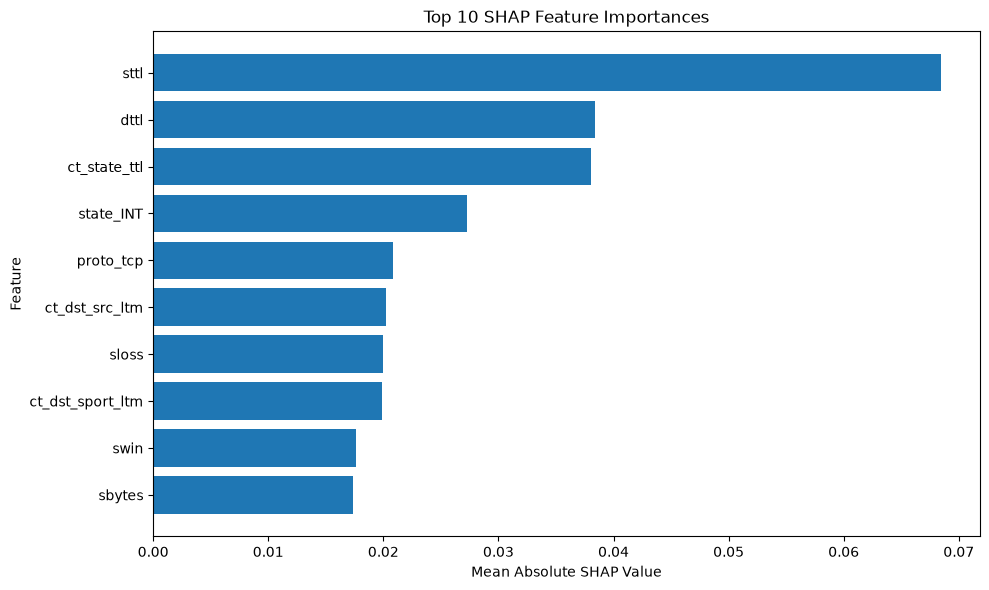

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Number of model input features
n_features = X_shap.shape[1]

# Try to recover the original feature names
if "X_known_df" in globals() and isinstance(X_known_df, pd.DataFrame):
    actual_names = X_known_df.columns.tolist()
elif "X_df" in globals() and isinstance(X_df, pd.DataFrame):
    actual_names = X_df.columns.tolist()
elif "X_processed" in globals() and isinstance(X_processed, pd.DataFrame):
    actual_names = X_processed.columns.tolist()
else:
    actual_names = []

# Use names only if the number of columns matches
if len(actual_names) == n_features:
    feature_labels = actual_names
else:
    feature_labels = [f"Feature_{i}" for i in range(n_features)]
    print("Original feature names not recovered.")
    print("Using placeholder names until the original mapping is found.")

# Calculate global importance from the SHAP values
importance = np.abs(attack_shap).mean(axis=0)

importance_df = pd.DataFrame({
    "Feature": feature_labels,
    "Mean_Absolute_SHAP": importance
}).sort_values("Mean_Absolute_SHAP", ascending=False)

print("Top 10 influential features:")
print(importance_df.head(10).to_string(index=False))

# Plot
plot_df = importance_df.head(10).sort_values("Mean_Absolute_SHAP")

plt.figure(figsize=(10, 6))
plt.barh(plot_df["Feature"], plot_df["Mean_Absolute_SHAP"])
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 10 SHAP Feature Importances")
plt.tight_layout()
plt.show()
